### Min-Max Scaling
Min-Max Scaling is a feature scaling technique that transforms the values of a feature into a fixed range, usually between 0 and 1, by subtracting the minimum value and dividing by the difference between the maximum and minimum values.

**Formula:**

$$
X' = \frac{X - X_{\min}}{X_{\max} - X_{\min}}
$$

In [2]:
#IMPORTING BASIC LIBRARIES
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
#Loading our dataset
data=pd.read_csv(r'D:\programming\datasets\wine_data.csv')
data.head()

,class_label,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,OD280/OD315_of_diluted_wines,proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [9]:
#we need only first three columns so:-
df=pd.read_csv(r'D:\programming\datasets\wine_data.csv',usecols=[0,1,2])
df.columns=['class_label' , 'alcohol' , 'malic_acid']
df.head()

,class_label,alcohol,malic_acid
0,1,14.23,1.71
1,1,13.20,1.78
2,1,13.16,2.36
3,1,14.37,1.95
4,1,13.24,2.59


In [10]:
df.info() #gives column type and non-null values sum

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   class_label  178 non-null    int64  
 1   alcohol      178 non-null    float64
 2   malic_acid   178 non-null    float64
dtypes: float64(2), int64(1)
memory usage: 4.3 KB


In [ ]:
df.sample(7) #we get 3 class labels - 1,2,3

,class_label,alcohol,malic_acid
156,3,13.84,4.12
20,1,14.06,1.63
69,2,12.21,1.19
81,2,12.72,1.81
173,3,13.71,5.65
79,2,12.70,3.87
112,2,11.76,2.68


In [14]:
#Dividing our categorical and numerical data
df_categorical=df['class_label']
df_numerical=df.drop(columns=['class_label'])

In [17]:
df_numerical.sample(5)

,alcohol,malic_acid
158,14.34,1.68
50,13.05,1.73
92,12.69,1.53
109,11.61,1.35
169,13.40,4.60


In [18]:
df_categorical.sample(5)

54     1
27     1
167    3
82     2
174    3
Name: class_label, dtype: int64

## TRAIN_TEST_SPLIT ##

In [19]:
from sklearn.model_selection import train_test_split

X_train , X_test , y_train , y_test = train_test_split(df_numerical , df_categorical , test_size=0.3 , random_state=42)


In [31]:
np.round(X_train.max(),1)

alcohol       14.8
malic_acid     5.8
dtype: float64

In [30]:
np.round(X_train.min(),1)

alcohol       11.0
malic_acid     0.9
dtype: float64

## MIN_MAX SCALING ##

In [26]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
scaler.fit(X_train)

# In a Jupyter environment, please rerun this cell to show the HTML representation or trust the notebook.
# On GitHub, the HTML representation is unable to render, please try loading this page with nbviewer.org.

,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False
Name,Type,Value
"data_max_ data_max_: ndarray of shape (n_features,)Per feature maximum seen in the data.. versionadded:: 0.17 *data_max_*","ndarray[float64](2,)","[14.83, 5.8 ]"
"data_min_ data_min_: ndarray of shape (n_features,)Per feature minimum seen in the data.. versionadded:: 0.17 *data_min_*","ndarray[float64](2,)","[11.03, 0.89]"
"data_range_ data_range_: ndarray of shape (n_features,)Per feature range ``(data_max_ - data_min_)`` seen in the data.. versionadded:: 0.17 *data_range_*","ndarray[float64](2,)","[3.8 ,4.91]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['alcohol','malic_acid']"
"min_ min_: ndarray of shape (n_features,)Per feature adjustment for minimum. Equivalent to``min - X.min(axis=0) * self.scale_``","ndarray[float64](2,)","[-2.9 ,-0.18]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
"n_samples_seen_ n_samples_seen_: intThe number of samples processed by the estimator.It will be reset on new calls to fit, but increments across``partial_fit`` calls.",int,124


In [27]:
X_train_scaled=scaler.transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [ ]:
X_test_scaled #numpy matrix so lets convert it

array([[ 0.68684211,  0.45010183],
       [ 0.83684211,  0.64154786],
       [ 0.5       ,  0.3910387 ],
       [ 0.71052632,  0.12423625],
       [ 0.35263158,  0.05702648],
       [ 0.86052632,  0.20977597],
       [ 0.25526316,  0.51731161],
       [ 0.62368421,  0.61507128],
       [ 0.15263158,  0.09368635],
       [ 0.61315789,  0.3401222 ],
       [ 0.65      ,  0.18737271],
       [ 0.65      ,  0.45417515],
       [ 0.62631579,  0.60081466],
       [ 0.45789474,  0.51731161],
       [ 0.68421053,  0.18737271],
       [ 0.39210526,  0.31364562],
       [ 0.1       , -0.0305499 ],
       [ 0.27631579,  0.04887984],
       [ 0.74473684,  0.09368635],
       [ 0.27631579,  0.10183299],
       [ 0.83157895,  0.14256619],
       [ 0.54736842,  0.02443992],
       [ 0.34210526,  0.04276986],
       [ 0.62368421,  0.75560081],
       [ 0.45789474,  0.30549898],
       [ 0.72368421,  0.3808554 ],
       [ 0.36578947,  0.14663951],
       [ 0.35263158,  0.06517312],
       [ 0.27631579,

In [35]:
#conversion to dataframe
X_train_scaled=pd.DataFrame(X_train_scaled,columns=df_numerical.columns)
X_test_scaled=pd.DataFrame(X_test_scaled,columns=df_numerical.columns)

In [36]:
X_train_scaled

,alcohol,malic_acid
0,0.647368,0.549898
1,0.389474,0.171079
2,0.342105,0.020367
3,0.592105,0.152749
4,0.331579,0.395112
...,...,...
119,0.744737,0.126273
120,0.321053,0.171079
121,0.881579,0.199593
122,0.436842,0.130346


**Difference between X_train min and max before and after scaling**

In [28]:
np.round(X_train.describe(),1)

,alcohol,malic_acid
count,124.0,124.0
mean,13.0,2.4
std,0.8,1.1
min,11.0,0.9
25%,12.3,1.6
50%,12.9,1.9
75%,13.7,3.2
max,14.8,5.8


In [ ]:
np.round(X_train_scaled.describe(),1) #observe min and max

,alcohol,malic_acid
count,124.0,124.0
mean,0.5,0.3
std,0.2,0.2
min,0.0,0.0
25%,0.3,0.2
50%,0.5,0.2
75%,0.7,0.5
max,1.0,1.0


## GRAPHICAL REPRESENTATION ##

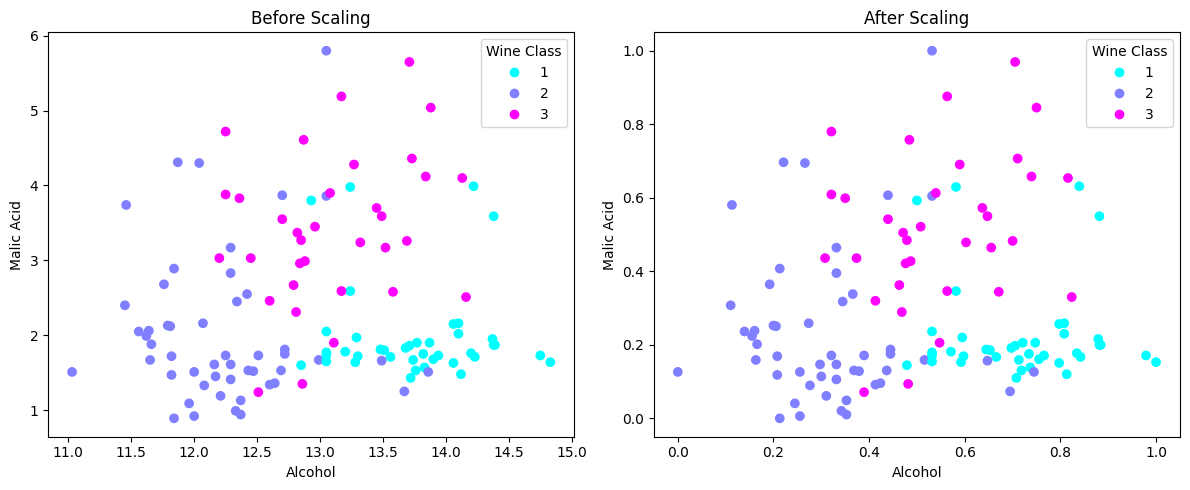

In [ ]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# Before scaling
scatter1 = ax1.scatter(
    X_train['alcohol'],
    X_train['malic_acid'],
    c=y_train,
    cmap='cool'
)
ax1.set_title('Before Scaling')
ax1.set_xlabel('Alcohol')
ax1.set_ylabel('Malic Acid')
ax1.legend(*scatter1.legend_elements(), title='Wine Class')

# After scaling
scatter2 = ax2.scatter(
    X_train_scaled['alcohol'],
    X_train_scaled['malic_acid'],
    c=y_train,
    cmap='cool'
)
ax2.set_title('After Scaling')
ax2.set_xlabel('Alcohol')
ax2.set_ylabel('Malic Acid')
ax2.legend(*scatter2.legend_elements(), title='Wine Class')

plt.tight_layout()
plt.show()

#only range changed to 0,1 rest graphical representation is same

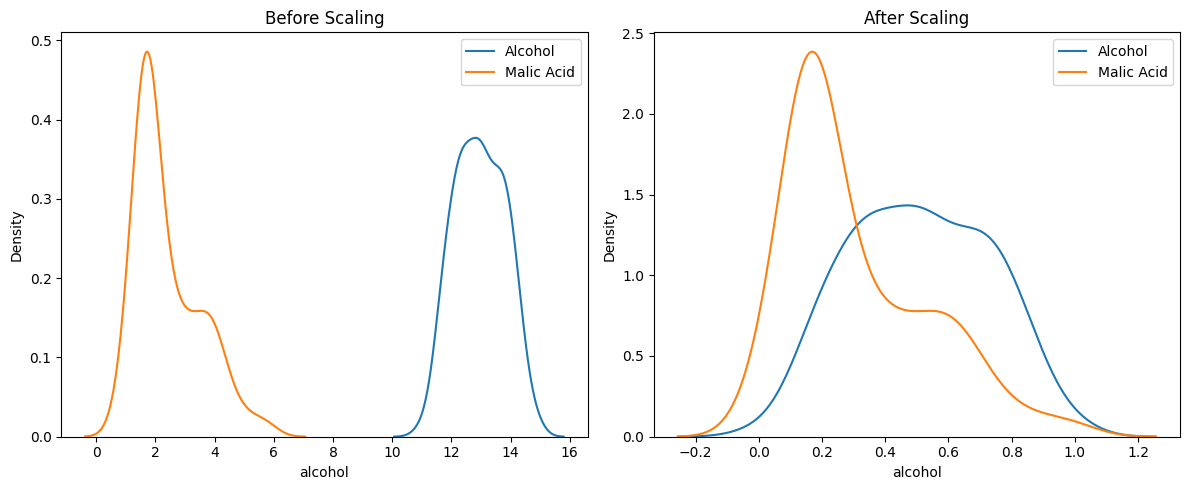

In [ ]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# Before scaling
sns.kdeplot(x=X_train['alcohol'], ax=ax1, label='Alcohol')
sns.kdeplot(x=X_train['malic_acid'], ax=ax1, label='Malic Acid')
ax1.set_title('Before Scaling')
ax1.legend()

# After scaling
sns.kdeplot(x=X_train_scaled['alcohol'], ax=ax2, label='Alcohol')
sns.kdeplot(x=X_train_scaled['malic_acid'], ax=ax2, label='Malic Acid')
ax2.set_title('After Scaling')
ax2.legend()

plt.tight_layout()
plt.show()

#we can oberserve that after scaling both lies in same range.